In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from gensim.models import Word2Vec
from sklearn.model_selection import train_test_split

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

In [13]:
df = pd.read_csv("CBOW/IMDB Dataset.csv")

display(df)
print(df.shape)

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive
...,...,...
49995,I thought this movie did a down right good job...,positive
49996,"Bad plot, bad dialogue, bad acting, idiotic di...",negative
49997,I am a Catholic taught in parochial elementary...,negative
49998,I'm going to have to disagree with the previou...,negative


(50000, 2)


In [3]:
x = df["review"]
y = df["sentiment"].map({"positive": 1, "negative": 0})

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42
)

In [4]:
train_words = [review.lower().split() for review in x_train]
test_words = [review.lower().split() for review in x_test]

print(train_words[0][:20])

["that's", 'what', 'i', 'kept', 'asking', 'myself', 'during', 'the', 'many', 'fights,', 'screaming', 'matches,', 'swearing', 'and', 'general', 'mayhem', 'that', 'permeate', 'the', '84']


In [5]:
cbow = Word2Vec(
    sentences=train_words,
    vector_size=100,
    window=5,
    min_count=2,
    sg=0,
    epochs=5
)

print("Vocabulary size:", len(cbow.wv))

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Vocabulary size: 133684


In [6]:
x_train_embed = np.array([cbow.wv.get_mean_vector(r) for r in train_words])
x_test_embed = np.array([cbow.wv.get_mean_vector(r) for r in test_words])

print(x_train_embed.shape)
print(x_test_embed.shape)

(40000, 100)
(10000, 100)


In [7]:
model = Sequential([
    Dense(64, activation="relu", input_shape=(100,)),
    Dense(32, activation="relu"),
    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         6,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,577 (33.50 KB)

 Trainable params: 8,577 (33.50 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
history = model.fit(
    x_train_embed, y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.2
)

Epoch 1/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 648us/step - accuracy: 0.7463 - loss: 0.5196 - val_accuracy: 0.8181 - val_loss: 0.4061
Epoch 2/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 0s 521us/step - accuracy: 0.8204 - loss: 0.4009 - val_accuracy: 0.8298 - val_loss: 0.3824
Epoch 3/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 0s 520us/step - accuracy: 0.8260 - loss: 0.3891 - val_accuracy: 0.8324 - val_loss: 0.3775
Epoch 4/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 0s 520us/step - accuracy: 0.8280 - loss: 0.3871 - val_accuracy: 0.8349 - val_loss: 0.3740
Epoch 5/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 0s 532us/step - accuracy: 0.8318 - loss: 0.3796 - val_accuracy: 0.8384 - val_loss: 0.3671


In [9]:
loss, accuracy = model.evaluate(x_test_embed, y_test)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 351us/step - accuracy: 0.8398 - loss: 0.3686
Test Loss: 0.3686077296733856
Test Accuracy: 0.8398000001907349


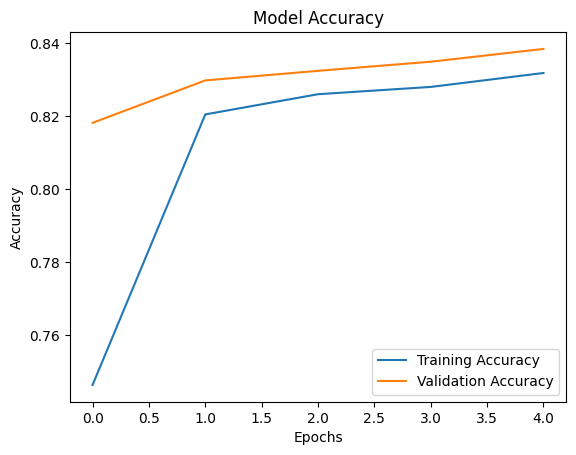

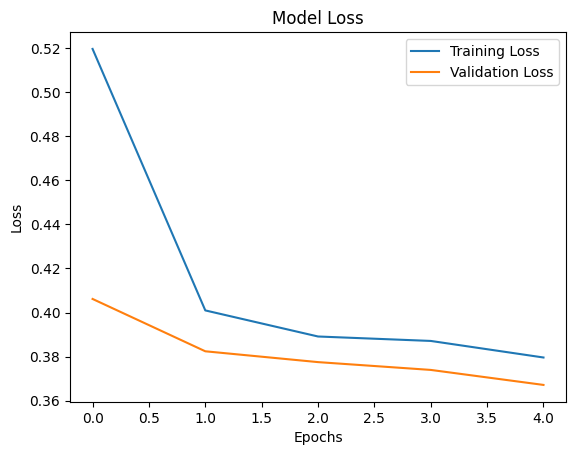

In [10]:
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()